# Visualisation Sandbox

**Author:** Cornel Gübeli
**Date:** 2026-09-22

## Objective
This notebook is a sandbox for data visualisation using matplotlib and seaborn

## Resources
Seaborne Documentation: https://seaborn.pydata.org/index.html
Matplotlib Documentation: https://matplotlib.org/stable/users/index


In [2]:
# import packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
# import dataframe from a csv file
df = pd.read_csv("https://gist.githubusercontent.com/slopp/ce3b90b9168f2f921784de84fa445651/raw/4ecf3041f0ed4913e7c230758733948bc561f434/penguins.csv")
df.head()

,rowid,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,1,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,2,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,3,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,4,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,5,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


<Axes: xlabel='bill_length_mm', ylabel='bill_depth_mm'>

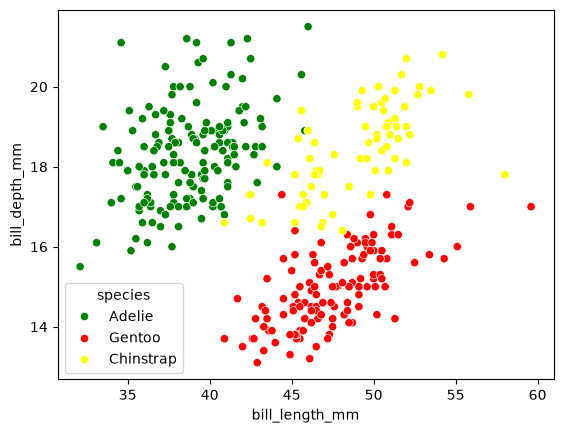

In [9]:
sns.scatterplot(data=df, 
x="bill_length_mm", 
y="bill_depth_mm", 
hue="species", 
palette={"Adelie": "green", "Chinstrap": "yellow", "Gentoo": "red"})

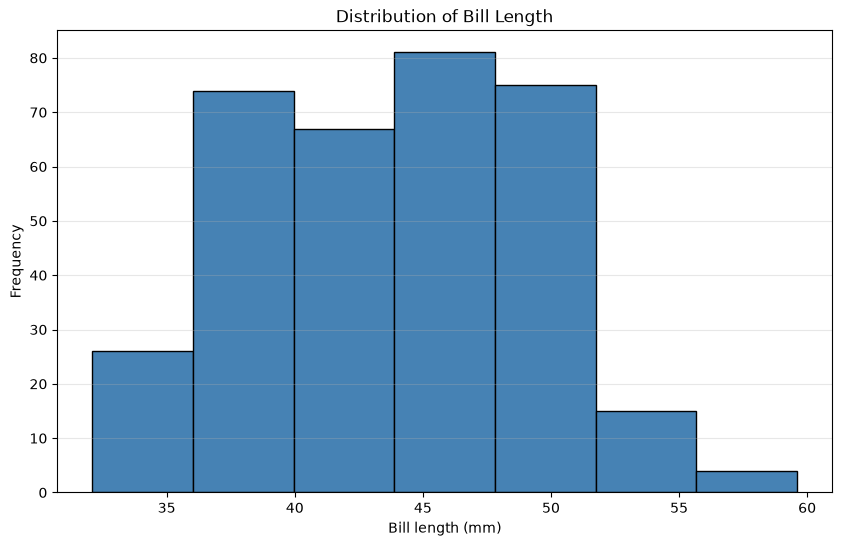

In [16]:
# Histogram of bill length
plt.figure(figsize=(10, 6))

plt.hist(
    df["bill_length_mm"].dropna(),
    bins=7,
    color="steelblue",
    edgecolor="black"
)

plt.title("Distribution of Bill Length")
plt.xlabel("Bill length (mm)")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.3)

plt.show()

training score: 0.923 | test score: 0.913 | n_estimators: 1


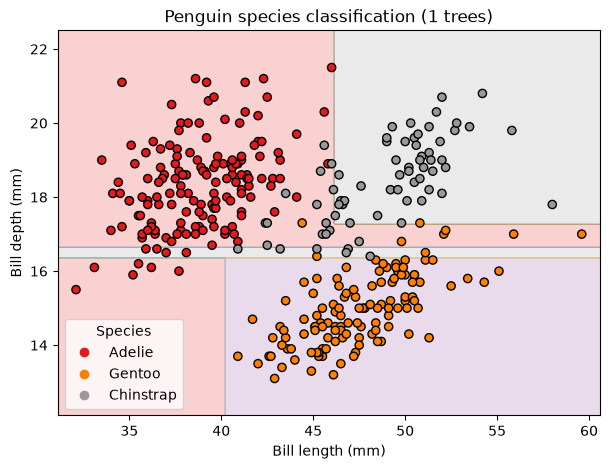

training score: 0.974 | test score: 0.957 | n_estimators: 4


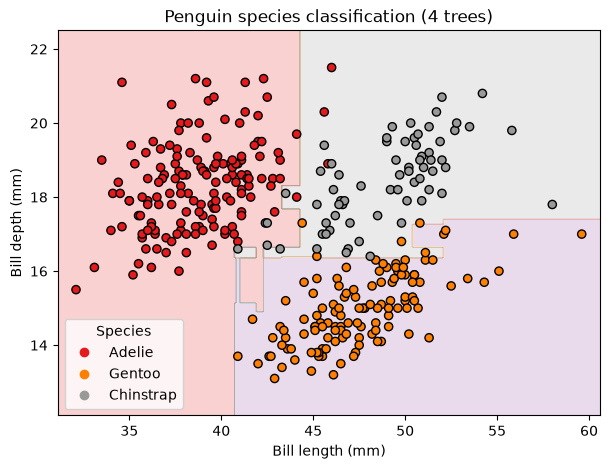

training score: 0.982 | test score: 0.971 | n_estimators: 50


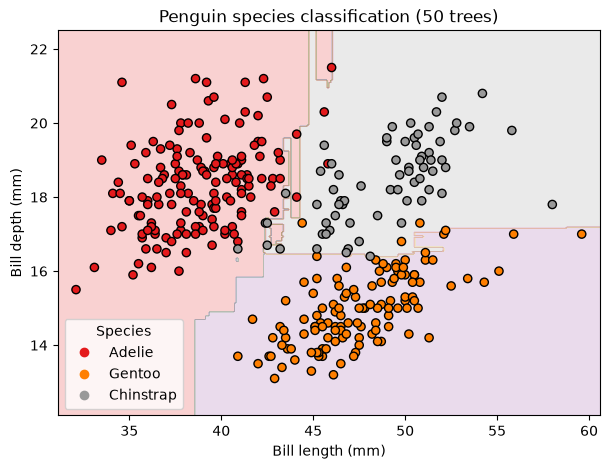

In [17]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Use two numeric measurements to classify penguin species.
features = ["bill_length_mm", "bill_depth_mm"]
penguins = df[features + ["species"]].dropna()

X = penguins[features].to_numpy()
y, species = pd.factorize(penguins["species"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Plot the classifier's decision regions and the observations.
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

for n_estimators in (1, 4, 50):
    classifier = RandomForestClassifier(
        max_depth=4,
        n_estimators=n_estimators,
        random_state=42
    )
    classifier.fit(X_train, y_train)

    train_score = classifier.score(X_train, y_train)
    test_score = classifier.score(X_test, y_test)
    print(
        f"training score: {train_score:.3f} | "
        f"test score: {test_score:.3f} | "
        f"n_estimators: {n_estimators}"
    )

    predictions = classifier.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    plt.figure(figsize=(7, 5))
    plt.contourf(xx, yy, predictions, alpha=0.2, cmap="Set1")
    scatter = plt.scatter(
        X[:, 0], X[:, 1], c=y, cmap="Set1", edgecolor="black", s=35
    )
    plt.xlabel("Bill length (mm)")
    plt.ylabel("Bill depth (mm)")
    plt.title(f"Penguin species classification ({n_estimators} trees)")
    plt.legend(
        handles=scatter.legend_elements()[0],
        labels=species.tolist(),
        title="Species"
    )
    plt.show()